In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the Iris dataset
df = pd.read_csv("../data/iris.csv")

# Display the first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check column names
print("\nColumn names:")
print(df.columns.tolist())

# Check species distribution
print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [3]:
# Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [4]:
# Count duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 1


In [5]:
# Statistical summary of numerical features
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


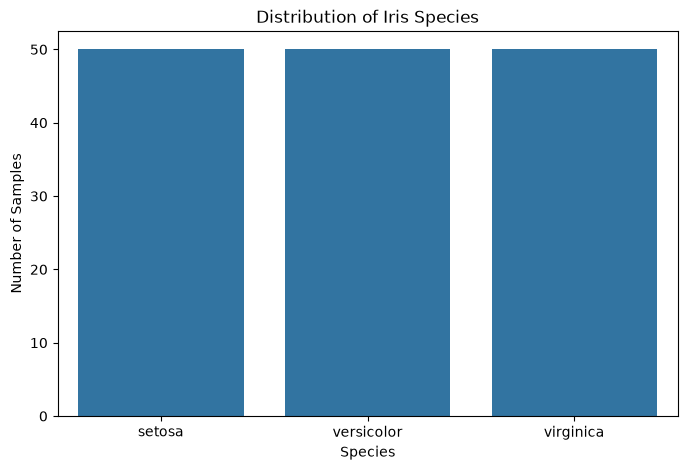

In [6]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Samples")

plt.show()

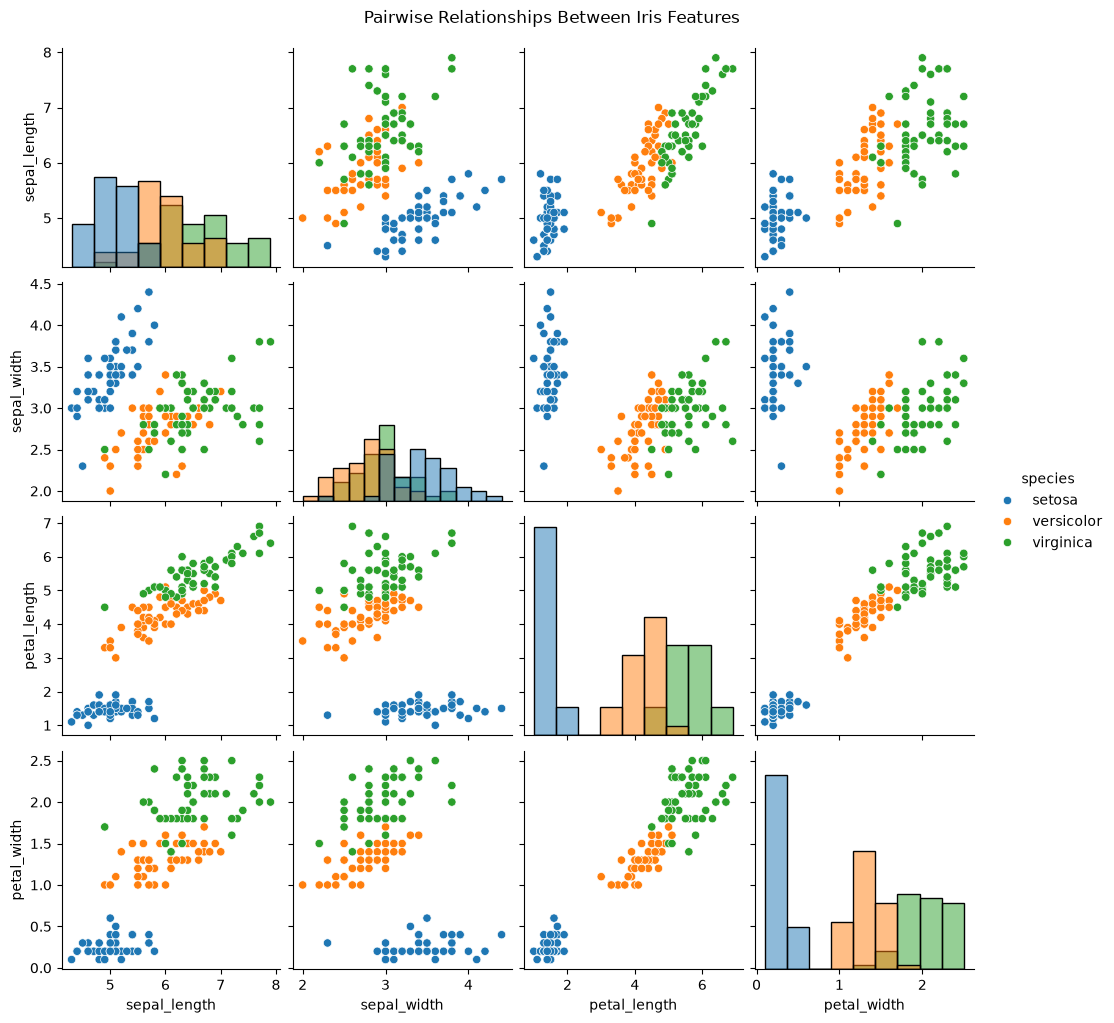

In [7]:
sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle(
    "Pairwise Relationships Between Iris Features",
    y=1.02
)

plt.show()

In [8]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (149, 5)
Remaining duplicates: 0


In [9]:
# Separate features and target
X = df.drop("species", axis=1)
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (149, 4)
Target shape: (149,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining species distribution:")
print(y_train.value_counts())

print("\nTesting species distribution:")
print(y_test.value_counts())

Training features: (119, 4)
Testing features: (30, 4)

Training species distribution:
species
setosa        40
versicolor    40
virginica     39
Name: count, dtype: int64

Testing species distribution:
species
versicolor    10
virginica     10
setosa        10
Name: count, dtype: int64


In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled testing data:", X_test_scaled.shape)

Scaled training data: (119, 4)
Scaled testing data: (30, 4)


In [12]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
log_model = LogisticRegression(max_iter=200, random_state=42)

# Train the model using scaled training data
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [13]:
# Predict species using the test data
y_pred_log = log_model.predict(X_test_scaled)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_pred_log[:10])

print("\nFirst 10 actual species:")
print(y_test.iloc[:10].values)

First 10 predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']

First 10 actual species:
<StringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica']
Length: 10, dtype: str


In [14]:
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    random_state=42,
    max_depth=3
)

# Train the model
tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [15]:
# Predict species using the test data
y_pred_tree = tree_model.predict(X_test)

print("First 10 predictions:")
print(y_pred_tree[:10])

print("\nFirst 10 actual species:")
print(y_test.iloc[:10].values)

First 10 predictions:
['versicolor' 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor'
 'versicolor' 'setosa' 'virginica' 'virginica']

First 10 actual species:
<StringArray>
['versicolor', 'versicolor',  'virginica',     'setosa',  'virginica',
 'versicolor', 'versicolor',     'setosa',  'virginica',  'virginica']
Length: 10, dtype: str


In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [17]:
# Evaluate Logistic Regression
log_accuracy = accuracy_score(y_test, y_pred_log)

log_precision = precision_score(
    y_test, y_pred_log, average="weighted"
)

log_recall = recall_score(
    y_test, y_pred_log, average="weighted"
)

log_f1 = f1_score(
    y_test, y_pred_log, average="weighted"
)

print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(log_accuracy, 4))
print("Precision:", round(log_precision, 4))
print("Recall:", round(log_recall, 4))
print("F1-score:", round(log_f1, 4))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.9333
Precision: 0.9333
Recall: 0.9333
F1-score: 0.9333


In [18]:
# Evaluate Decision Tree
tree_accuracy = accuracy_score(y_test, y_pred_tree)

tree_precision = precision_score(
    y_test, y_pred_tree, average="weighted"
)

tree_recall = recall_score(
    y_test, y_pred_tree, average="weighted"
)

tree_f1 = f1_score(
    y_test, y_pred_tree, average="weighted"
)

print("DECISION TREE RESULTS")
print("---------------------")
print("Accuracy:", round(tree_accuracy, 4))
print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1-score:", round(tree_f1, 4))

DECISION TREE RESULTS
---------------------
Accuracy: 0.9667
Precision: 0.9697
Recall: 0.9667
F1-score: 0.9666


In [19]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [log_accuracy, tree_accuracy],
    "Precision": [log_precision, tree_precision],
    "Recall": [log_recall, tree_recall],
    "F1-score": [log_f1, tree_f1]
})

results

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.966667,0.969697,0.966667,0.966583


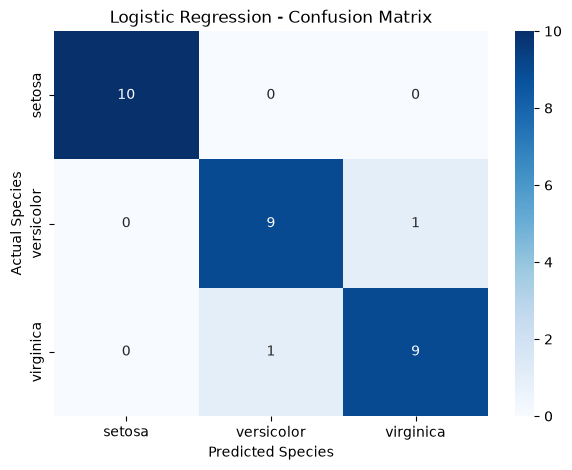

In [25]:
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix
cm_log = confusion_matrix(y_test, y_pred_log, labels=log_model.classes_)

# Plot heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=log_model.classes_,
    yticklabels=log_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.savefig("../results/logistic_regression_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

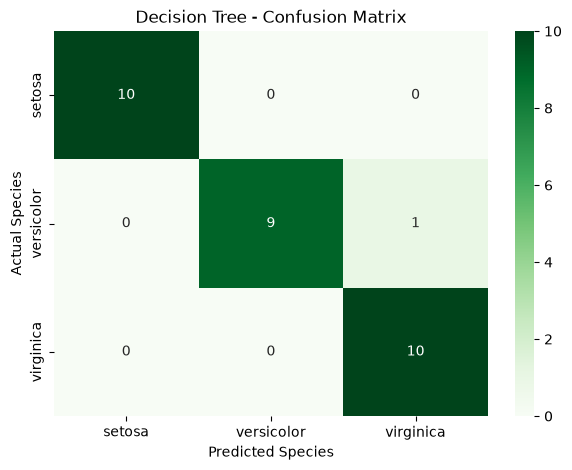

In [26]:
# Calculate confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree, labels=tree_model.classes_)

# Plot heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=tree_model.classes_,
    yticklabels=tree_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.savefig("../results/decision_tree_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

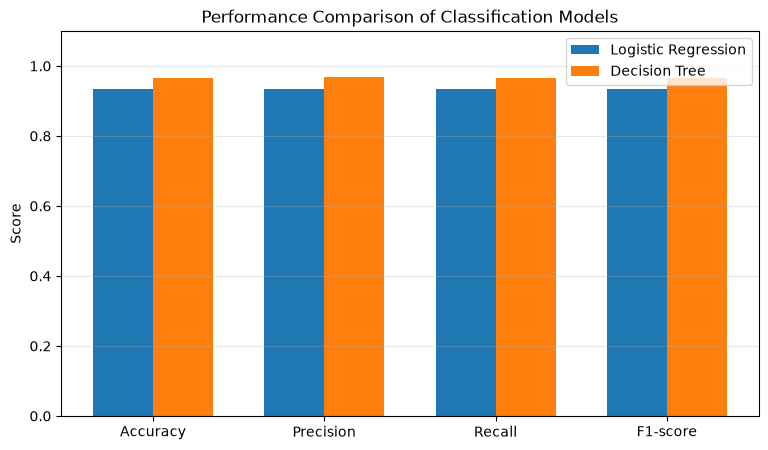

In [24]:
# Compare model performance visually

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

log_scores = [
    log_accuracy,
    log_precision,
    log_recall,
    log_f1
]

tree_scores = [
    tree_accuracy,
    tree_precision,
    tree_recall,
    tree_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, log_scores, width, label="Logistic Regression")
plt.bar(x + width/2, tree_scores, width, label="Decision Tree")

plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("Performance Comparison of Classification Models")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("../results/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


### Confusion Matrix Analysis

The confusion matrices show that both classification models performed well on the Iris dataset.

The Logistic Regression model correctly classified 28 out of 30 test samples. It classified all Setosa flowers correctly but confused one Versicolor flower with Virginica and one Virginica flower with Versicolor.

The Decision Tree model correctly classified 29 out of 30 test samples. It classified all Setosa and Virginica flowers correctly, but confused one Versicolor flower with Virginica.

Overall, the Decision Tree achieved better performance than Logistic Regression on this test set. Both models had difficulty distinguishing Versicolor and Virginica, which may be explained by the overlap in their feature measurements.

# Final Conclusion

In this project, I developed a multi-class classification pipeline using the Iris dataset. The dataset initially contained 150 observations, four numerical features and three flower species. After checking the data, I identified and removed one duplicate row, leaving 149 observations.

Exploratory Data Analysis helped me understand the feature distributions and relationships between the three species. The pairplot showed that Setosa is relatively easy to distinguish, while Versicolor and Virginica have some overlapping feature measurements.

I split the dataset into 80% training data and 20% testing data. I also applied StandardScaler to the features, fitting it only on the training data to avoid data leakage.

I trained and evaluated two supervised machine-learning algorithms: Logistic Regression and Decision Tree.

The results were:

| Metric | Logistic Regression | Decision Tree |
|---|---:|---:|
| Accuracy | 93.33% | 96.67% |
| Precision | 93.33% | 96.97% |
| Recall | 93.33% | 96.67% |
| F1-score | 93.33% | 96.66% |

The Decision Tree achieved the best overall performance, correctly classifying 29 out of 30 test samples, compared with 28 out of 30 for Logistic Regression.

Based on these results, I conclude that the Decision Tree performed slightly better on this particular test split. However, both models achieved strong classification performance.

This project helped me understand the complete supervised machine-learning workflow, from data preprocessing and visualization to model training, evaluation and comparison.